<a href="https://colab.research.google.com/github/jrangelg/Artificial-intelligence/blob/main/riesgo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Teoría de Optimización de Portafolios: Markowitz vs. Black-Litterman

---

## 1. Teoría Moderna de Portafolios (Markowitz)

El modelo de Markowitz (Media-Varianza) busca maximizar el retorno esperado de un portafolio para un nivel determinado de riesgo, o equivalentemente, minimizar la varianza para un nivel determinado de retorno.

### Retorno Esperado del Portafolio
El retorno esperado $E(R_p)$ es una combinación lineal ponderada de los retornos esperados de cada activo:

$$ E(R_p) = w^T \mu = \sum_{i=1}^{N} w_i E(R_i) $$

Donde:
- $w$: Vector de pesos de los activos en el portafolio $(N \times 1)$.
- $\mu$: Vector de retornos esperados históricos de los activos $(N \times 1)$.

### Riesgo (Varianza) del Portafolio
La varianza del portafolio $\sigma_p^2$ considera las covarianzas entre todos los pares de activos:

$$ \sigma_p^2 = w^T \Sigma w = \sum_{i=1}^{N} \sum_{j=1}^{N} w_i w_j \sigma_{ij} $$

Donde:
- $\Sigma$: Matriz de covarianza de los retornos de los activos $(N \times N)$.

### Optimización (Máximo Ratio de Sharpe)
La función objetivo habitual maximiza el rendimiento ajustado por riesgo (Ratio de Sharpe):

$$ \max_{w} \frac{w^T \mu - R_f}{\sqrt{w^T \Sigma w}} $$

Sujeto a las restricciones:

$$ \sum_{i=1}^{N} w_i = 1 \quad \text{y} \quad w_i \geq 0 \quad \forall i $$

---

## 2. Modelo de Black-Litterman

El modelo de Black-Litterman resuelve la inestabilidad de Markowitz combinando la distribución de equilibrio del mercado (Prior) con las visiones subjetivas del inversionista (Views) mediante la inferencia Bayesiana.

### Step 1: Retornos Implícitos de Equilibrio (Prior)
Se calculan los retornos de equilibrio a partir de la capitalización de mercado:

$$ \Pi = \lambda \Sigma w_{mkt} $$

Donde:
- $\Pi$: Vector de retornos implícitos de equilibrio $(N \times 1)$.
- $\lambda$: Coeficiente de aversión al riesgo del mercado.
- $w_{mkt}$: Vector de pesos de capitalización de mercado $(N \times 1)$.

### Step 2: Incorporación de las Visiones (Views)
Las opiniones del inversionista se expresan como:

$$ P \cdot E(R) = Q + \epsilon $$

Donde:
- $P$: Matriz que identifica los activos involucrados en cada visión $(K \times N)$.
- $Q$: Vector con el rendimiento esperado de cada visión $(K \times 1)$.
- $\Omega$: Matriz diagonal de covarianza de los errores de las visiones $(K \times K)$.

$$ \Omega = \text{diag}\left( P (\tau \Sigma) P^T \right) $$

### Step 3: Retornos Esperados Ajustados (Posterior)
Combinando el prior con las visiones mediante el Teorema de Bayes, se obtiene el nuevo vector de retornos esperados $\mu_{BL}$:

$$ \mu_{BL} = \left[ (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \right]^{-1} \left[ (\tau \Sigma)^{-1} \Pi + P^T \Omega^{-1} Q \right] $$

Donde:
- $\tau$: Escalar de incertidumbre sobre la estimación de la matriz de covarianza (típicamente $0.025 \leq \tau \leq 0.05$).

### Step 4: Matriz de Covarianza Ajustada
La covarianza ajustada del modelo posterior incorpora la incertidumbre de la estimación:

$$ \Sigma_{BL} = \Sigma + \left[ (\tau \Sigma)^{-1} + P^T \Omega^{-1} P \right]^{-1} $$

Finalmente, los valores $\mu_{BL}$ y $\Sigma_{BL}$ se utilizan en la optimización tradicional de Markowitz para obtener los pesos óptimos $w_{BL}$.

[*********************100%***********************]  5 of 5 completed

Descargando datos...



=== ASIGNACIÓN DE PESOS OPTIMIZADA ===
      Markowitz Tradicional Black-Litterman
AAPL                 62.25%          16.29%
MSFT                   0.0%          42.88%
GOOGL                  0.0%          13.64%
AMZN                   0.0%           9.94%
JPM                  37.75%          17.25%


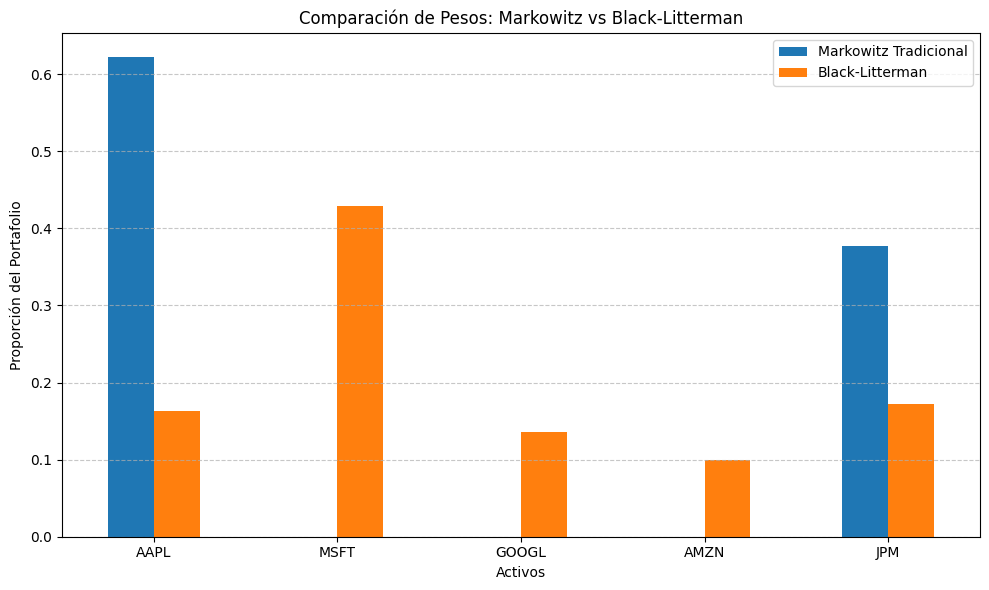

In [ ]:
# 1. Instalación de dependencias
!pip install yfinance numpy pandas scipy matplotlib -q

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 2. Descarga de Datos
# ---------------------------------------------------------
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'JPM']
start_date = '2020-01-01'
end_date = '2024-01-01'

print("Descargando datos...")
# Se descargan los precios usando auto_adjust=True para obtener directo los cierres ajustados
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)

# Extraer los precios de cierre de forma segura
if 'Close' in data:
    df = data['Close']
else:
    df = data

returns = df.pct_change().dropna()

# Parámetros base
num_assets = len(tickers)
risk_free_rate = 0.04  # Tasa libre de riesgo (4% anual)
cov_matrix = returns.cov() * 252  # Matriz de covarianza anualizada
mean_returns = returns.mean() * 252  # Retornos esperados históricos anualizados

# ---------------------------------------------------------
# 3. Portafolio de Markowitz (Máximo Ratio de Sharpe)
# ---------------------------------------------------------
def portfolio_performance(weights, mean_returns, cov_matrix):
    ret = np.sum(mean_returns * weights)
    std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return ret, std

def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate):
    p_ret, p_std = portfolio_performance(weights, mean_returns, cov_matrix)
    return -(p_ret - risk_free_rate) / p_std

# Restricciones: suma de pesos = 1, pesos entre 0 y 1 (sin ventas en corto)
constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0, 1) for _ in range(num_assets))
init_guess = num_assets * [1.0 / num_assets]

# Optimización de Markowitz
opt_markowitz = minimize(
    negative_sharpe, init_guess,
    args=(mean_returns, cov_matrix, risk_free_rate),
    method='SLSQP', bounds=bounds, constraints=constraints
)

weights_markowitz = opt_markowitz.x

# ---------------------------------------------------------
# 4. Modelo de Black-Litterman
# ---------------------------------------------------------
# A) Retornos de equilibrio del mercado (Prior Implícito)
delta = 2.5  # Aversión al riesgo promedio del mercado
market_weights = np.array([0.25, 0.25, 0.20, 0.15, 0.15])  # Pesos aproximados de mercado
pi = delta * np.dot(cov_matrix, market_weights)  # Retornos implícitos (Prior)

# B) Definición de Visiones (Views) del Inversionista
# Visión 1 (Absoluta): AAPL tendrá un retorno del 15%
# Visión 2 (Relativa): MSFT superará a GOOGL en un 5%
P = np.array([
    [1, 0, 0, 0, 0],   # AAPL
    [0, 1, -1, 0, 0]   # MSFT - GOOGL
])
Q = np.array([0.15, 0.05])  # Rendimientos esperados de las visiones

# C) Matriz de incertidumbre de las visiones (Omega)
tau = 0.05  # Escalar de incertidumbre
omega = np.diag(np.diag(tau * np.dot(np.dot(P, cov_matrix), P.T)))

# D) Cálculo de Retornos Esperados Ajustados (Posterior)
tau_cov = tau * cov_matrix
inv_tau_cov = np.linalg.inv(tau_cov)
inv_omega = np.linalg.inv(omega)

# Fórmula de Black-Litterman para retornos esperados ajustados (BL Mean)
bl_mean = np.linalg.inv(inv_tau_cov + np.dot(P.T, np.dot(inv_omega, P))) @ \
          (np.dot(inv_tau_cov, pi) + np.dot(P.T, np.dot(inv_omega, Q)))

# E) Optimización con Pesos de Black-Litterman
opt_bl = minimize(
    negative_sharpe, init_guess,
    args=(bl_mean, cov_matrix, risk_free_rate),
    method='SLSQP', bounds=bounds, constraints=constraints
)

weights_bl = opt_bl.x

# ---------------------------------------------------------
# 5. Comparación y Resultados
# ---------------------------------------------------------
df_weights = pd.DataFrame({
    'Markowitz Tradicional': weights_markowitz,
    'Black-Litterman': weights_bl
}, index=tickers)

print("\n=== ASIGNACIÓN DE PESOS OPTIMIZADA ===")
print((df_weights * 100).round(2).astype(str) + '%')

# Graficar resultados
df_weights.plot(kind='bar', figsize=(10, 6))
plt.title('Comparación de Pesos: Markowitz vs Black-Litterman')
plt.ylabel('Proporción del Portafolio')
plt.xlabel('Activos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Diversificación de Portafolios Basada en Árboles

---

## 1. Agrupamiento Jerárquico de Riesgo (Hierarchical Risk Parity - HRP)

El método **HRP** utiliza árboles de decisión (dendrogramas) y teoría de grafos para solucionar la inestabilidad matemática de la inversión de la matriz de covarianza de Markowitz ($ \Sigma^{-1} $), logrando una diversificación estructural basada en la topología de los activos.

---

### Paso 1: Métrica de Distancia Geodésica
Se convierte la matriz de correlación $\rho_{ij}$ entre los retornos de dos activos en una métrica de distancia euclidiana válida $d_{ij}$:

$$ d_{ij} = \sqrt{2 \left( 1 - \rho_{ij} \right)} $$

Donde:
- $\rho_{ij} = \frac{\sigma_{ij}}{\sigma_i \sigma_j}$: Coeficiente de correlación de Pearson entre los activos $i$ y $j$.
- $d_{ij} \in [0, 2]$: Distancia entre activos ($0$ para correlación perfecta $+1$, $2$ para correlación perfecta $-1$).

---

### Paso 2: Matriz de Distancia Agregada (Linkage Matrix)
Se construye una matriz de distancias entre clusters $D$ calculando la distancia euclidiana entre los vectores de distancia de cada par de activos:

$$ D(i, j) = \sqrt{\sum_{k=1}^{N} \left( d_{ik} - d_{jk} \right)^2} $$

A partir de $D$, se aplica un algoritmo de **agrupamiento jerárquico** (e.g., *single*, *complete* o *ward linkage*) para generar una estructura en árbol en forma de **dendrograma**.

---

### Paso 3: Ordenamiento Jerárquico y Cuasi-Diagonalización
El árbol resultante se reorganiza mediante un recorrido jerárquico (*tree traversal*) para colocar los activos similares en hojas adyacentes, reordenando la matriz de covarianza $\Sigma$ en una matriz cuasi-diagonal $\Sigma^*$:

$$ \Sigma^* = P \Sigma P^T $$

Donde $P$ es una matriz de permutación obtenida mediante el ordenamiento topológico del árbol.

---

### Paso 4: Bipartición Recursiva y Asignación de Pesos
El árbol se divide recursivamente de arriba hacia abajo (*top-down*) en dos subgrupos $C_1$ y $C_2$. La varianza agregada $\tilde{\sigma}^2_V$ de un cluster $C_V$ se calcula mediante pesos inversos a la varianza:

$$ w_i = \frac{\frac{1}{\sigma_i^2}}{\sum_{j \in C_V} \frac{1}{\sigma_j^2}}, \quad \forall i \in C_V $$

$$ \tilde{\sigma}^2_V = w_V^T \Sigma_{V} w_V $$

La asignación de pesos entre los dos sub-árboles $C_1$ y $C_2$ en cada nodo del árbol se realiza de forma inversamente proporcional a sus varianzas:

$$ \alpha_1 = 1 - \frac{\tilde{\sigma}^2_1}{\tilde{\sigma}^2_1 + \tilde{\sigma}^2_2} $$

$$ \alpha_2 = 1 - \alpha_1 $$

Los pesos finales de los activos $w_i$ se obtienen multiplicando los factores $\alpha$ a lo largo del camino desde la raíz hasta la hoja correspondiente del árbol:

$$ w_i = \prod_{k \in \text{Ruta}(i)} \alpha_k $$

---

## 2. Árbol de Recubrimiento Mínimo (Minimum Spanning Tree - MST)

El método **MST** simplifica la red de interconexiones financieras reduciendo las $N(N-1)/2$ relaciones de correlación a solo $N-1$ conexiones esenciales (aristas) sin ciclos.

---

### Construcción del Grafo y Filtro Topológico
A partir de la matriz de distancias $d_{ij}$, se busca el árbol $T = (V, E)$ que minimice la suma total de las distancias entre activos conectados:

$$ \min_{T \subset G} \sum_{(i, j) \in E(T)} d_{ij} $$

Sujeto a:
- $|V| = N$ (Todos los activos están incluidos).
- $|E| = N - 1$ (El árbol no contiene ciclos).

---

### Centralidad y Diversificación por Grado Topológico
Los activos actuarán como nodos centrales (*hubs*) o nodos periféricos según su grado de centralidad $k_i$ en el árbol:

$$ k_i = \sum_{j \in V} A_{ij} $$

Donde $A_{ij}$ es la matriz de adyacencia del MST ($A_{ij} = 1$ si existe una arista directa entre $i$ y $j$, $0$ de lo contrario).

La diversificación se logra asignando menor peso a los activos centrales (alto riesgo sistémico por estar altamente conectados) y mayor peso a las hojas del árbol (activos periféricos con baja conectividad global):

$$ w_i \propto \frac{1}{k_i \cdot \sigma_i^2} $$

[*********************100%***********************]  5 of 5 completed

Descargando datos...



=== COMPARACIÓN DE PESOS OPTIMIZADOS ===
      Markowitz Black-Litterman HRP (Dendrograma) MST (Redes)
AAPL     62.25%          16.29%            12.28%      13.89%
MSFT       0.0%          42.88%            13.01%      22.04%
GOOGL      0.0%          13.64%            21.87%      27.84%
AMZN       0.0%           9.94%            24.03%      26.42%
JPM      37.75%          17.25%            28.81%       9.81%


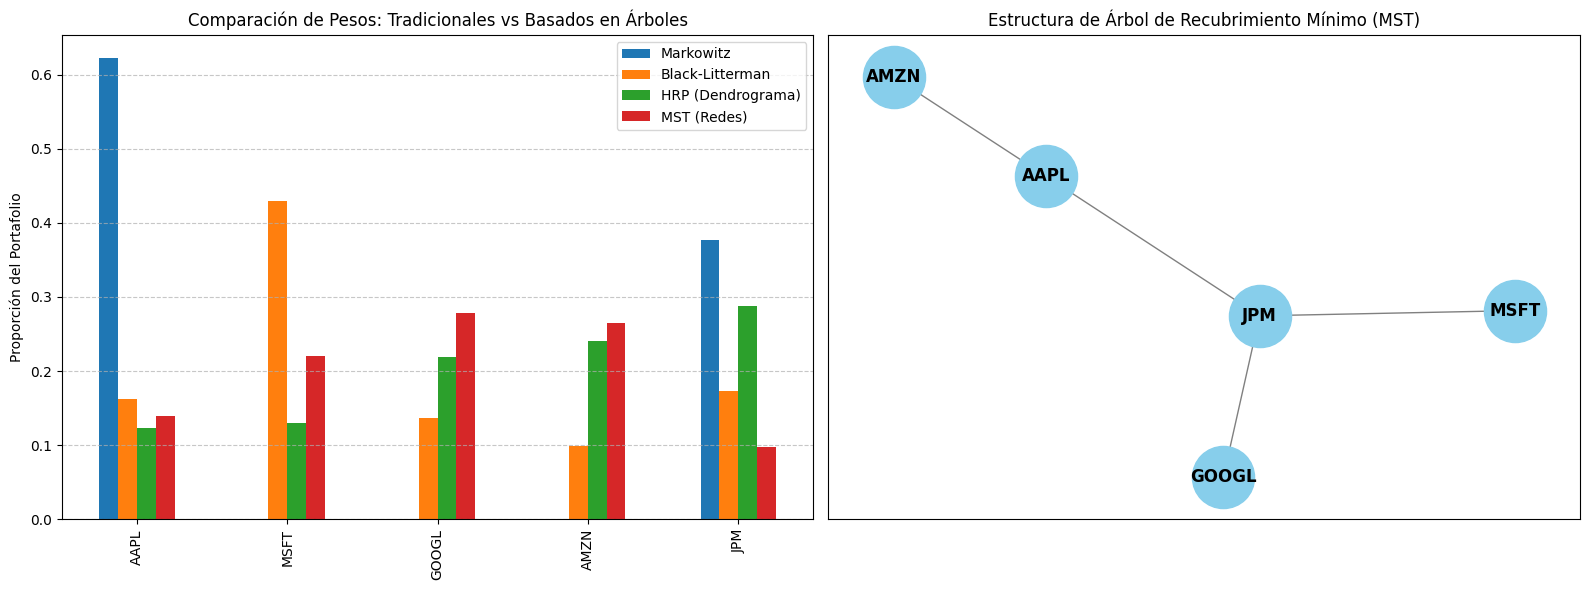

In [ ]:
# 1. Instalación de dependencias requeridas
!pip install yfinance numpy pandas scipy matplotlib networkx -q

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import networkx as nx
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 2. Descarga de Datos
# ---------------------------------------------------------
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'JPM']
start_date = '2020-01-01'
end_date = '2024-01-01'

print("Descargando datos...")
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
df = data['Close'] if 'Close' in data else data
returns = df.pct_change().dropna()

num_assets = len(tickers)
risk_free_rate = 0.04
cov_matrix = returns.cov() * 252
corr_matrix = returns.corr()
mean_returns = returns.mean() * 252

# ---------------------------------------------------------
# 3. Modelos Previos: Markowitz y Black-Litterman
# ---------------------------------------------------------
def portfolio_performance(weights, mean_returns, cov_matrix):
    ret = np.sum(mean_returns * weights)
    std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return ret, std

def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate):
    p_ret, p_std = portfolio_performance(weights, mean_returns, cov_matrix)
    return -(p_ret - risk_free_rate) / p_std

constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0, 1) for _ in range(num_assets))
init_guess = num_assets * [1.0 / num_assets]

# Markowitz
opt_markowitz = minimize(negative_sharpe, init_guess, args=(mean_returns, cov_matrix, risk_free_rate),
                         method='SLSQP', bounds=bounds, constraints=constraints)
weights_markowitz = opt_markowitz.x

# Black-Litterman
delta = 2.5
market_weights = np.array([0.25, 0.25, 0.20, 0.15, 0.15])
pi = delta * np.dot(cov_matrix, market_weights)
P = np.array([[1, 0, 0, 0, 0], [0, 1, -1, 0, 0]])
Q = np.array([0.15, 0.05])
tau = 0.05
omega = np.diag(np.diag(tau * np.dot(np.dot(P, cov_matrix), P.T)))
tau_cov = tau * cov_matrix
inv_tau_cov = np.linalg.inv(tau_cov)
inv_omega = np.linalg.inv(omega)

bl_mean = np.linalg.inv(inv_tau_cov + np.dot(P.T, np.dot(inv_omega, P))) @ \
          (np.dot(inv_tau_cov, pi) + np.dot(P.T, np.dot(inv_omega, Q)))

opt_bl = minimize(negative_sharpe, init_guess, args=(bl_mean, cov_matrix, risk_free_rate),
                  method='SLSQP', bounds=bounds, constraints=constraints)
weights_bl = opt_bl.x

# ---------------------------------------------------------
# 4. Modelo Basado en Árbol 1: Hierarchical Risk Parity (HRP)
# ---------------------------------------------------------
# Distancia euclidiana sobre la correlación
dist_matrix = np.sqrt(2 * (1 - corr_matrix))

# Agrupamiento Jerárquico
link = linkage(squareform(dist_matrix.values), method='single')
sort_idx = leaves_list(link)
ordered_tickers = corr_matrix.columns[sort_idx]

def get_cluster_var(cov, items):
    cov_slice = cov.loc[items, items]
    w = 1.0 / np.diag(cov_slice)
    w /= w.sum()
    return np.dot(w.T, np.dot(cov_slice, w))

def get_hrp_weights(cov, items):
    weights = pd.Series(1.0, index=items)
    clusters = [items]
    while len(clusters) > 0:
        clusters = [c[i:j] for c in clusters for i, j in [(0, len(c) // 2), (len(c) // 2, len(c))] if len(c) > 1]
        for i in range(0, len(clusters), 2):
            c1, c2 = clusters[i], clusters[i + 1]
            v1 = get_cluster_var(cov, c1)
            v2 = get_cluster_var(cov, c2)
            alpha = 1 - v1 / (v1 + v2)
            weights[c1] *= alpha
            weights[c2] *= (1 - alpha)
    return weights

weights_hrp_series = get_hrp_weights(cov_matrix, list(ordered_tickers))
weights_hrp = weights_hrp_series.reindex(tickers).values

# ---------------------------------------------------------
# 5. Modelo Basado en Árbol 2: Minimum Spanning Tree (MST)
# ---------------------------------------------------------
G = nx.Graph()
for i in range(num_assets):
    for j in range(i + 1, num_assets):
        G.add_edge(tickers[i], tickers[j], weight=dist_matrix.iloc[i, j])

mst = nx.minimum_spanning_tree(G)
degrees = dict(mst.degree())

# Pesos inversos al grado de centralidad y varianza
variances = np.diag(cov_matrix)
inv_degrees = np.array([1.0 / (degrees[t] * variances[i]) for i, t in enumerate(tickers)])
weights_mst = inv_degrees / np.sum(inv_degrees)

# ---------------------------------------------------------
# 6. Cuadro Comparativo y Gráficas
# ---------------------------------------------------------
df_weights = pd.DataFrame({
    'Markowitz': weights_markowitz,
    'Black-Litterman': weights_bl,
    'HRP (Dendrograma)': weights_hrp,
    'MST (Redes)': weights_mst
}, index=tickers)

print("\n=== COMPARACIÓN DE PESOS OPTIMIZADOS ===")
print((df_weights * 100).round(2).astype(str) + '%')

# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico de barras comparativo
df_weights.plot(kind='bar', ax=axes[0])
axes[0].set_title('Comparación de Pesos: Tradicionales vs Basados en Árboles')
axes[0].set_ylabel('Proporción del Portafolio')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Gráfico de la red Árbol de Recubrimiento Mínimo (MST)
pos = nx.spring_layout(mst, seed=42)
nx.draw_networkx(mst, pos, ax=axes[1], with_labels=True, node_color='skyblue',
                node_size=2000, font_weight='bold', edge_color='gray')
axes[1].set_title('Estructura de Árbol de Recubrimiento Mínimo (MST)')

plt.tight_layout()
plt.show()